In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import friedmanchisquare, wilcoxon

In [3]:
RESULTS_DIR = "../results/2026-06-25_full_benchmark"

SUMMARY_PATH = os.path.join(
    RESULTS_DIR,
    "summaries",
    "all_models_all_series_summary.csv"
)

OUTPUT_DIR = "../results/statistical_tests"
FIGURE_DIR = "../figures/statistical_tests"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

MODEL_ORDER = [
    "naive",
    "drift_naive",
    "ar1",
    "xgboost_level",
    "xgboost_increment",
    "lstm_level",
    "lstm_increment",
    "gru_level",
    "tcn_level",
    "simple_causal_transformer",
    "residual_causal_transformer",
    "causal_encoder_transformer",
    "patchtst_level"
]

SERIES_ORDER = [
    "linear_gaussian",
    "linear_student_t",
    "nonlinear_gaussian",
    "nonlinear_student_t"
]

def model_label(name):
    return name.replace("_", " ").title()

In [4]:
summary_df = pd.read_csv(SUMMARY_PATH)

summary_df.head()

,series,model,collapse_sigma,collapse_status,last_sigma,last_rmse,last_rmse_over_sigma,last_directional_accuracy
0,linear_gaussian,naive,> 2.0,not confirmed,2.0,2.023541,1.011771,0.494990
1,linear_gaussian,drift_naive,> 2.0,not confirmed,2.0,2.023946,1.011973,0.494990
2,linear_gaussian,ar1,1.5555555555555554,confirmed,2.0,2.892125,1.446062,0.472946
3,linear_gaussian,xgboost_level,1.5555555555555554,confirmed,2.0,4.500876,2.250438,0.452906
4,linear_gaussian,xgboost_increment,1.5555555555555554,confirmed,2.0,2.033826,1.016913,0.496994


In [5]:
metric = "last_rmse_over_sigma"

performance_df = summary_df.pivot(
    index="series",
    columns="model",
    values=metric
).reindex(SERIES_ORDER)[MODEL_ORDER]

performance_df

model,naive,drift_naive,ar1,xgboost_level,xgboost_increment,lstm_level,lstm_increment,gru_level,tcn_level,simple_causal_transformer,residual_causal_transformer,causal_encoder_transformer,patchtst_level
series,,,,,,,,,,,,,
linear_gaussian,1.011771,1.011973,1.446062,2.250438,1.016913,1.482918,1.011333,1.332119,1.056453,1.576244,1.011601,2.910704,2.325068
linear_student_t,1.000695,1.000628,1.449897,3.642725,1.042574,1.644975,1.001671,1.572981,1.001977,3.193503,1.004232,3.353397,2.907750
nonlinear_gaussian,0.998621,0.998528,1.439671,17.657368,1.016825,11.284824,1.001197,8.873041,1.214648,17.652979,1.010014,20.253624,18.000164
nonlinear_student_t,1.335462,1.335738,1.857666,1.819458,1.352302,3.117885,1.334687,2.288204,1.363820,1.598768,1.335635,3.696812,3.071600


In [6]:
rank_df = performance_df.rank(axis=1, method="average", ascending=True)

rank_df

model,naive,drift_naive,ar1,xgboost_level,xgboost_increment,lstm_level,lstm_increment,gru_level,tcn_level,simple_causal_transformer,residual_causal_transformer,causal_encoder_transformer,patchtst_level
series,,,,,,,,,,,,,
linear_gaussian,3.0,4.0,8.0,11.0,5.0,9.0,1.0,7.0,6.0,10.0,2.0,13.0,12.0
linear_student_t,2.0,1.0,7.0,13.0,6.0,9.0,3.0,8.0,4.0,11.0,5.0,12.0,10.0
nonlinear_gaussian,2.0,1.0,7.0,11.0,5.0,9.0,3.0,8.0,6.0,10.0,4.0,13.0,12.0
nonlinear_student_t,2.0,4.0,9.0,8.0,5.0,12.0,1.0,10.0,6.0,7.0,3.0,13.0,11.0


In [7]:
average_ranks = rank_df.mean(axis=0).sort_values()

average_ranks_df = pd.DataFrame({
    "model": average_ranks.index,
    "average_rank": average_ranks.values
})

average_ranks_df

,model,average_rank
0,lstm_increment,2.00
1,naive,2.25
2,drift_naive,2.50
3,residual_causal_transformer,3.50
4,xgboost_increment,5.25
5,tcn_level,5.50
6,ar1,7.75
7,gru_level,8.25
8,simple_causal_transformer,9.50
9,lstm_level,9.75


In [8]:
average_ranks_df.to_csv(
    os.path.join(OUTPUT_DIR, "average_ranks.csv"),
    index=False
)

In [9]:
friedman_input = [
    performance_df[model].values
    for model in MODEL_ORDER
]

friedman_stat, friedman_p = friedmanchisquare(*friedman_input)

friedman_results = pd.DataFrame({
    "test": ["Friedman"],
    "statistic": [friedman_stat],
    "p_value": [friedman_p],
    "n_datasets": [performance_df.shape[0]],
    "n_models": [performance_df.shape[1]]
})

friedman_results

,test,statistic,p_value,n_datasets,n_models
0,Friedman,43.912088,0.000016,4,13


In [10]:
friedman_results.to_csv(
    os.path.join(OUTPUT_DIR, "friedman_test.csv"),
    index=False
)

In [11]:
alpha = 0.05

if friedman_p < alpha:
    print(f"Friedman test is significant: p = {friedman_p:.6f}")
    print("Conclusion: At least one model performs significantly differently.")
else:
    print(f"Friedman test is not significant: p = {friedman_p:.6f}")
    print("Conclusion: No statistically significant performance difference detected.")

Friedman test is significant: p = 0.000016
Conclusion: At least one model performs significantly differently.


In [12]:
N = performance_df.shape[0]
k = performance_df.shape[1]

# Conservative approximate q_alpha for many models at alpha=0.05.
# For thesis-level interpretation this is acceptable.
# If needed later, replace with exact Studentized range value.
q_alpha = 3.314

critical_difference = q_alpha * np.sqrt(
    k * (k + 1) / (6 * N)
)

critical_difference

9.126044396853072

In [13]:
nemenyi_info = pd.DataFrame({
    "n_datasets": [N],
    "n_models": [k],
    "q_alpha_approx": [q_alpha],
    "critical_difference": [critical_difference]
})

nemenyi_info.to_csv(
    os.path.join(OUTPUT_DIR, "nemenyi_critical_difference.csv"),
    index=False
)

nemenyi_info

,n_datasets,n_models,q_alpha_approx,critical_difference
0,4,13,3.314,9.126044


In [14]:
models = average_ranks.index.tolist()

nemenyi_pairs = []

for i in range(len(models)):
    for j in range(i + 1, len(models)):

        model_i = models[i]
        model_j = models[j]

        rank_diff = abs(
            average_ranks[model_i] - average_ranks[model_j]
        )

        significant = rank_diff > critical_difference

        nemenyi_pairs.append({
            "model_1": model_i,
            "model_2": model_j,
            "average_rank_1": average_ranks[model_i],
            "average_rank_2": average_ranks[model_j],
            "rank_difference": rank_diff,
            "critical_difference": critical_difference,
            "significant": significant
        })

nemenyi_pairs_df = pd.DataFrame(nemenyi_pairs)

nemenyi_pairs_df.sort_values(
    "rank_difference",
    ascending=False
).head(20)

,model_1,model_2,average_rank_1,average_rank_2,rank_difference,critical_difference,significant
11,lstm_increment,causal_encoder_transformer,2.00,12.75,10.75,9.126044,True
22,naive,causal_encoder_transformer,2.25,12.75,10.50,9.126044,True
32,drift_naive,causal_encoder_transformer,2.50,12.75,10.25,9.126044,True
10,lstm_increment,patchtst_level,2.00,11.25,9.25,9.126044,True
41,residual_causal_transformer,causal_encoder_transformer,3.50,12.75,9.25,9.126044,True
21,naive,patchtst_level,2.25,11.25,9.00,9.126044,False
9,lstm_increment,xgboost_level,2.00,10.75,8.75,9.126044,False
31,drift_naive,patchtst_level,2.50,11.25,8.75,9.126044,False
20,naive,xgboost_level,2.25,10.75,8.50,9.126044,False
30,drift_naive,xgboost_level,2.50,10.75,8.25,9.126044,False


In [15]:
nemenyi_pairs_df.to_csv(
    os.path.join(OUTPUT_DIR, "nemenyi_pairwise_rank_differences.csv"),
    index=False
)

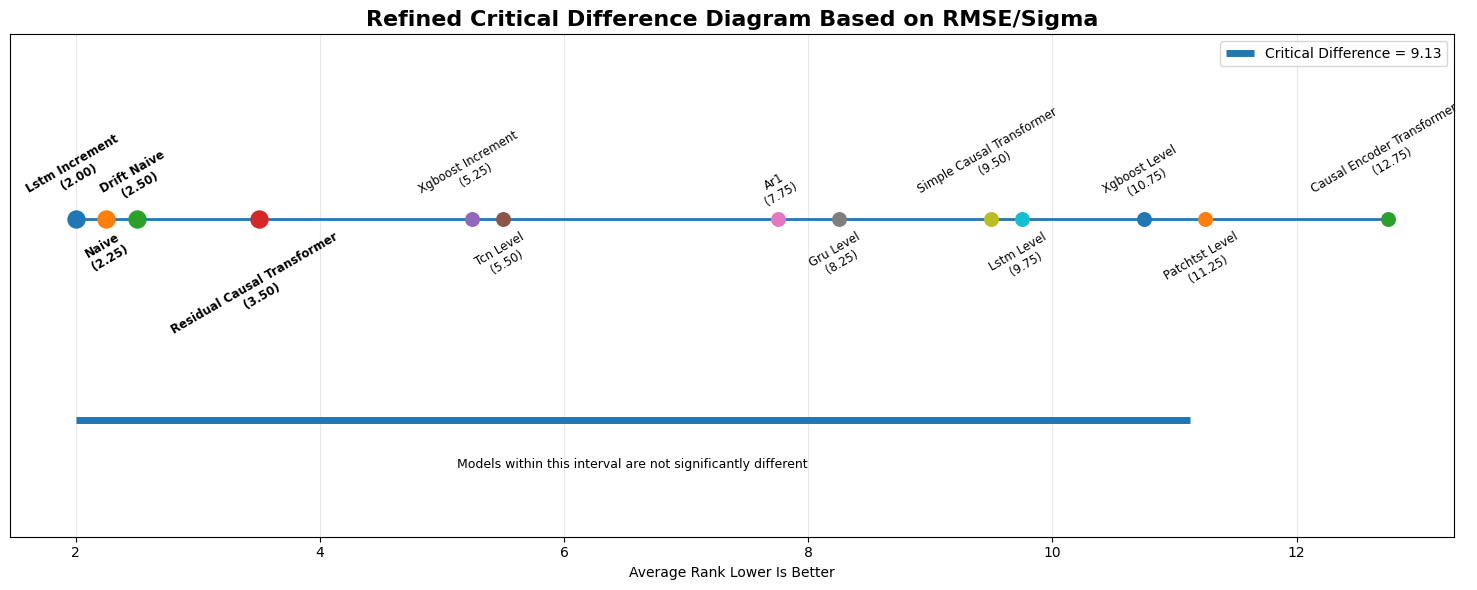

../figures/statistical_tests\refined_critical_difference_diagram.png


In [37]:
plot_df = average_ranks_df.sort_values("average_rank").reset_index(drop=True)

best_models = {
    "lstm_increment",
    "naive",
    "residual_causal_transformer",
    "drift_naive"
}

plt.figure(figsize=(15, 6))

x = plot_df["average_rank"].values
y = np.zeros(len(plot_df))

for _, row in plot_df.iterrows():
    model = row["model"]
    rank = row["average_rank"]

    if model in best_models:
        marker_size = 150
        fontweight = "bold"
    else:
        marker_size = 95
        fontweight = "normal"

    plt.scatter(
        rank,
        0,
        s=marker_size,
        zorder=3
    )

    vertical_offset = 0.02 if _ % 2 == 0 else -0.02
    va = "bottom" if _ % 2 == 0 else "top"

    plt.text(
        rank,
        vertical_offset,
        f"{model_label(model)}\n({rank:.2f})",
        ha="center",
        va=va,
        rotation=30,
        fontsize=8.5,
        fontweight=fontweight
    )

plt.hlines(
    y=0,
    xmin=plot_df["average_rank"].min(),
    xmax=plot_df["average_rank"].max(),
    linewidth=2
)

best_rank = plot_df["average_rank"].min()

plt.hlines(
    y=-0.38,
    xmin=best_rank,
    xmax=best_rank + critical_difference,
    linewidth=5,
    label=f"Critical Difference = {critical_difference:.2f}"
)

plt.text(
    best_rank + critical_difference / 2,
    -0.47,
    "Models within this interval are not significantly different",
    ha="center",
    fontsize=9
)

plt.xlabel("Average Rank Lower Is Better")
plt.yticks([])

plt.title(
    "Refined Critical Difference Diagram Based on RMSE/Sigma",
    fontsize=16,
    fontweight="bold"
)

plt.grid(axis="x", alpha=0.3)
plt.ylim(-0.6, 0.35)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()

path = os.path.join(
    FIGURE_DIR,
    "refined_critical_difference_diagram.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(path)

In [17]:
best_model = average_ranks.index[0]

wilcoxon_rows = []

for model in MODEL_ORDER:

    if model == best_model:
        continue

    try:
        stat, p_value = wilcoxon(
            performance_df[best_model],
            performance_df[model],
            alternative="less"
        )

        wilcoxon_rows.append({
            "best_model": best_model,
            "comparison_model": model,
            "wilcoxon_statistic": stat,
            "p_value": p_value,
            "significant_at_0.05": p_value < 0.05
        })

    except Exception as e:
        wilcoxon_rows.append({
            "best_model": best_model,
            "comparison_model": model,
            "wilcoxon_statistic": None,
            "p_value": None,
            "significant_at_0.05": False,
            "error": str(e)
        })

wilcoxon_df = pd.DataFrame(wilcoxon_rows)

wilcoxon_df.sort_values("p_value")

,best_model,comparison_model,wilcoxon_statistic,p_value,significant_at_0.05
2,lstm_increment,ar1,0.0,0.0625,False
3,lstm_increment,xgboost_level,0.0,0.0625,False
4,lstm_increment,xgboost_increment,0.0,0.0625,False
5,lstm_increment,lstm_level,0.0,0.0625,False
6,lstm_increment,gru_level,0.0,0.0625,False
7,lstm_increment,tcn_level,0.0,0.0625,False
8,lstm_increment,simple_causal_transformer,0.0,0.0625,False
9,lstm_increment,residual_causal_transformer,0.0,0.0625,False
10,lstm_increment,causal_encoder_transformer,0.0,0.0625,False
11,lstm_increment,patchtst_level,0.0,0.0625,False


In [18]:
wilcoxon_df.to_csv(
    os.path.join(OUTPUT_DIR, "wilcoxon_against_best_model.csv"),
    index=False
)

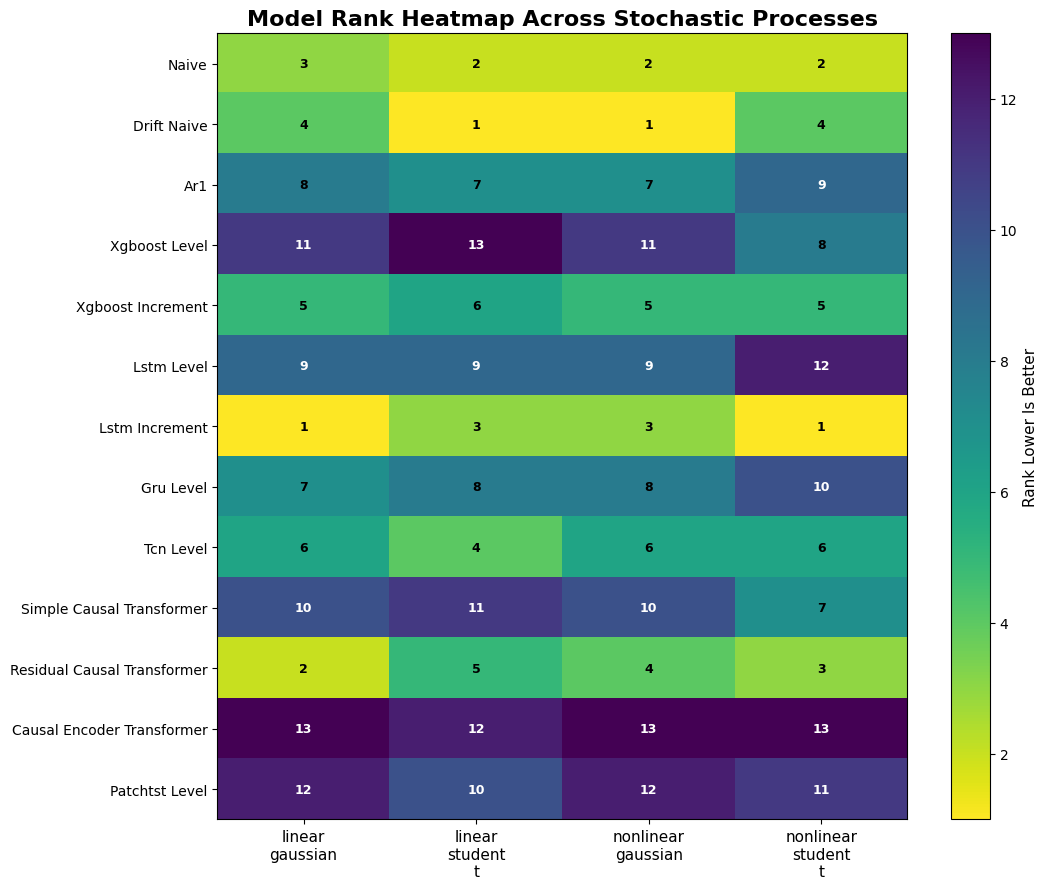

../figures/statistical_tests\refined_model_rank_heatmap.png


In [41]:
rank_heatmap_df = rank_df[MODEL_ORDER].T

plt.figure(figsize=(11, 9))

im = plt.imshow(
    rank_heatmap_df.values,
    aspect="auto",
    cmap="viridis_r",
    vmin=1,
    vmax=len(MODEL_ORDER)
)

plt.xticks(
    ticks=np.arange(len(rank_heatmap_df.columns)),
    labels=[s.replace("_", "\n") for s in rank_heatmap_df.columns],
    fontsize=11
)

plt.yticks(
    ticks=np.arange(len(rank_heatmap_df.index)),
    labels=[model_label(m) for m in rank_heatmap_df.index],
    fontsize=10
)

cbar = plt.colorbar(im)
cbar.set_label("Rank Lower Is Better", fontsize=11)

for i in range(rank_heatmap_df.shape[0]):
    for j in range(rank_heatmap_df.shape[1]):

        value = rank_heatmap_df.values[i, j]

        if value <= 3:
            text_color = "black"
        elif value >= 9:
            text_color = "white"
        else:
            text_color = "black"

        plt.text(
            j,
            i,
            f"{value:.0f}",
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold",
            color=text_color
        )

plt.title(
    "Model Rank Heatmap Across Stochastic Processes",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

path = os.path.join(
    FIGURE_DIR,
    "refined_model_rank_heatmap.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(path)

In [38]:
decision = "Reject H0" if friedman_p < 0.05 else "Fail to reject H0"

conclusion = (
    "At least one model differs significantly."
    if friedman_p < 0.05
    else "No statistically significant difference detected."
)

friedman_summary_table = pd.DataFrame({
    "Item": [
        "Number of datasets",
        "Number of models",
        "Friedman statistic",
        "p-value",
        "Significance level",
        "Decision",
        "Conclusion"
    ],
    "Value": [
        performance_df.shape[0],
        performance_df.shape[1],
        f"{friedman_stat:.4f}",
        f"{friedman_p:.6f}",
        "0.05",
        decision,
        conclusion
    ]
})

friedman_summary_table

,Item,Value
0,Number of datasets,4
1,Number of models,13
2,Friedman statistic,43.9121
3,p-value,0.000016
4,Significance level,0.05
5,Decision,Reject H0
6,Conclusion,At least one model differs significantly.


In [39]:
friedman_summary_table.to_csv(
    os.path.join(OUTPUT_DIR, "friedman_summary_table.csv"),
    index=False
)

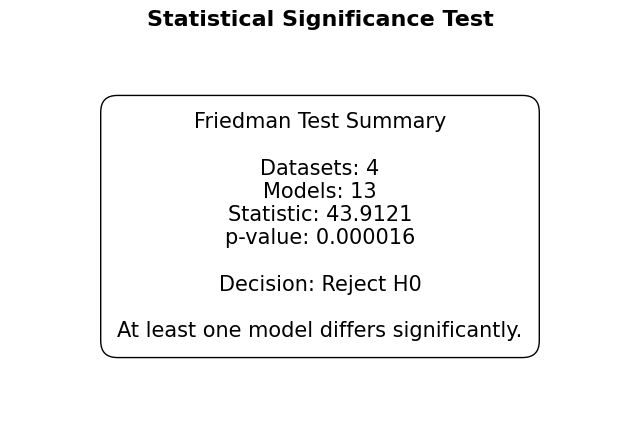

../figures/statistical_tests\friedman_test_summary_card.png


In [40]:
plt.figure(figsize=(8, 5))

plt.axis("off")

main_text = (
    "Friedman Test Summary\n\n"
    f"Datasets: {performance_df.shape[0]}\n"
    f"Models: {performance_df.shape[1]}\n"
    f"Statistic: {friedman_stat:.4f}\n"
    f"p-value: {friedman_p:.6f}\n\n"
    f"Decision: {decision}\n\n"
    f"{conclusion}"
)

plt.text(
    0.5,
    0.5,
    main_text,
    ha="center",
    va="center",
    fontsize=15,
    bbox=dict(
        boxstyle="round,pad=0.8",
        edgecolor="black",
        facecolor="white"
    )
)

plt.title(
    "Statistical Significance Test",
    fontsize=16,
    fontweight="bold"
)

path = os.path.join(
    FIGURE_DIR,
    "friedman_test_summary_card.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(path)